# Predicting Finishing Order of Formula 1 Races

### Predictions based on:
- Previous race finishing position
- Previous race qualifying postiion
- Average individual points per race after previous race
- Average team points per race after previous race

## Reading in CSV files of historic Formula 1 data from Kaggle:

In [55]:
# Import necessary libraries
import kagglehub
import pandas as pd
import os
import glob
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neural_network import MLPRegressor


# Download the dataset from Kaggle
path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

# Find all CSV files
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Load all CSV files into separate DataFrames
data = {}
for file in csv_files:
    # Extract filename without extension
    name = os.path.splitext(os.path.basename(file))[0]

    # Read CSV into DataFrame
    data[name] = pd.read_csv(file)

# Display imported datasets
for name, df in data.items():
    print(f"{name}: {df.shape}")


circuits: (77, 9)
status: (139, 2)
lap_times: (589081, 6)
sprint_results: (360, 16)
drivers: (861, 9)
races: (1125, 18)
constructors: (212, 5)
constructor_standings: (13391, 7)
qualifying: (10494, 9)
driver_standings: (34863, 7)
constructor_results: (12625, 5)
pit_stops: (11371, 7)
seasons: (75, 2)
results: (26759, 18)


## Feature engineering:
- Combining desired variables from historic F1 datasets
- Separating drivers into their own datasets
- Creating lag 1 varaibles to make predictions using a driver's previous race results
- Re-combining indicidual driver data into one dataset

In [56]:
results = data['results']

# Merge driver_standings into results
results = pd.merge(
    results,
    data['driver_standings'],
    on=['raceId', 'driverId'],
    how='left',
    suffixes=('', '_driver_standings')
)

# Merge constructor_standings into results
results = pd.merge(
    results,
    data['constructor_standings'],
    on=['raceId', 'constructorId'],
    how='left',
    suffixes=('', '_constructor_standings')
)

# Merge races into results
results = pd.merge(
    results,
    data['races'],
    on=['raceId'],
    how='left'
)

# Calculate average driver and constructor metrics per round
results['driver_points_per_round'] = results['points_driver_standings'] / results['round']
results['constructor_points_per_round'] = results['points_constructor_standings'] / results['round']
results['driver_wins_per_round'] = results['wins'] / results['round']
results['constructor_wins_per_round'] = results['wins_constructor_standings'] / results['round']

results['date'] = pd.to_datetime(results['date'])

# Select desired columns from results
results = results[[
    'resultId',
    'raceId',
    'date',
    'driverId',
    'constructorId',
    'grid',
    'positionOrder',
    'driver_points_per_round',
    'driver_wins_per_round',
    'constructor_points_per_round',
    'constructor_wins_per_round'
]]

# Replace N/A values with 0 and display the dataframe
results = results.fillna(0)
display(results.head(20))


,resultId,raceId,date,driverId,constructorId,grid,positionOrder,driver_points_per_round,driver_wins_per_round,constructor_points_per_round,constructor_wins_per_round
0,1,18,2008-03-16,1,1,1,1,10.0,1.0,14.0,1.0
1,2,18,2008-03-16,2,2,5,2,8.0,0.0,8.0,0.0
2,3,18,2008-03-16,3,3,7,3,6.0,0.0,9.0,0.0
3,4,18,2008-03-16,4,4,11,4,5.0,0.0,5.0,0.0
4,5,18,2008-03-16,5,1,3,5,4.0,0.0,14.0,1.0
5,6,18,2008-03-16,6,3,13,6,3.0,0.0,9.0,0.0
6,7,18,2008-03-16,7,5,17,7,2.0,0.0,2.0,0.0
7,8,18,2008-03-16,8,6,15,8,1.0,0.0,1.0,0.0
8,9,18,2008-03-16,9,2,2,9,0.0,0.0,8.0,0.0
9,10,18,2008-03-16,10,7,18,10,0.0,0.0,0.0,0.0


In [57]:
# Split results by driverId
driver_data = {}
for driver_id, group in results.groupby('driverId'):
    driver_data[driver_id] = group.copy()

# Access and display an individual driver's dataset
driver_1 = driver_data[1]
driver_1.head()

,resultId,raceId,date,driverId,constructorId,grid,positionOrder,driver_points_per_round,driver_wins_per_round,constructor_points_per_round,constructor_wins_per_round
0,1,18,2008-03-16,1,1,1,1,10.000000,1.000000,14.000000,1.000000
26,27,19,2008-03-23,1,1,9,5,7.000000,0.500000,12.000000,0.500000
56,57,20,2008-04-06,1,1,3,13,4.666667,0.333333,9.333333,0.333333
68,69,21,2008-04-27,1,1,5,3,5.000000,0.250000,8.500000,0.250000
89,90,22,2008-05-11,1,1,3,2,5.600000,0.200000,8.400000,0.200000


In [58]:
# Columns for which to create lag-1 variables
lag_columns = [
    'grid',
    'positionOrder',
    'driver_points_per_round',
    'driver_wins_per_round',
    'constructor_points_per_round',
    'constructor_wins_per_round'
]

# Create lag-1 variables for each driver
for driver_id, df in driver_data.items():

    # Sort observations chronologically by raceId
    df.sort_values('date', inplace=True)

    # Create lag-1 variables
    for col in lag_columns:
        df[f'{col}_lag1'] = df[col].shift(1)

# Columns to retain for prediction
selected_columns = [
    'resultId',
    'raceId',
    'date',
    'driverId',
    'constructorId',
    'positionOrder',
    'grid_lag1',
    'positionOrder_lag1',
    'driver_points_per_round_lag1',
    'driver_wins_per_round_lag1',
    'constructor_points_per_round_lag1',
    'constructor_wins_per_round_lag1'
]

# Select columns and remove the first row for each driver
for driver_id, df in driver_data.items():
    driver_data[driver_id] = df[selected_columns].iloc[1:]

# Combine all driver DataFrames
combined_results = pd.concat(driver_data.values(), ignore_index=True)

# Display the first five rows
combined_results.head()

# Dataset dimensions
print(combined_results.shape)

# Check missing values
print(combined_results.isnull().sum())

# Check number of unique drivers
print(combined_results['driverId'].nunique())

driver_data[1].head(10)

features = [
    'grid_lag1',
    'positionOrder_lag1',
    'driver_points_per_round_lag1',
    'driver_wins_per_round_lag1'
]

(25898, 12)
resultId                             0
raceId                               0
date                                 0
driverId                             0
constructorId                        0
positionOrder                        0
grid_lag1                            0
positionOrder_lag1                   0
driver_points_per_round_lag1         0
driver_wins_per_round_lag1           0
constructor_points_per_round_lag1    0
constructor_wins_per_round_lag1      0
dtype: int64
687


## Separating into training and testing sets
- Grouping by race and randomly allocating each race group

In [59]:
# Select predictors and target
X = combined_results[features]
y = combined_results['positionOrder']


# Keep raceId separately for grouping
groups = combined_results['raceId']

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]

X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Retain raceId for the test observations
test_data = combined_results.iloc[test_idx].copy()

## Analyzing the correlation between predictors and with the target variable

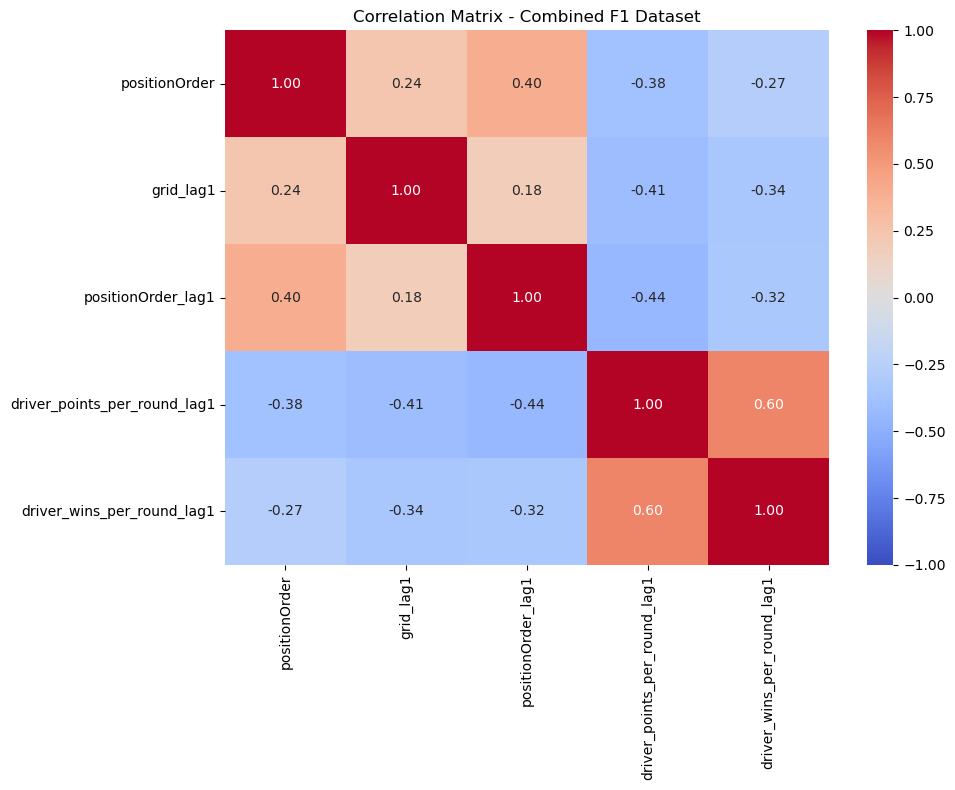

positionOrder_lag1              0.396372
driver_points_per_round_lag1   -0.376701
driver_wins_per_round_lag1     -0.273056
grid_lag1                       0.241326
Name: positionOrder, dtype: float64
                       Variable       VIF
0                     grid_lag1  2.502857
1            positionOrder_lag1  2.494900
2  driver_points_per_round_lag1  1.816383
3    driver_wins_per_round_lag1  1.740925


In [60]:
# Columns for correlation analysis
data_train = pd.concat([y_train, X_train], axis=1)

# Calculate correlation matrix
correlation_matrix = data_train.corr()

# Plot heatmap of correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Correlation Matrix - Combined F1 Dataset')
plt.tight_layout()
plt.show()

# Extract correlations with positionOrder
target_correlations = correlation_matrix['positionOrder'].drop('positionOrder')

# Sort by absolute correlation
target_correlations = target_correlations.reindex(
    target_correlations.abs().sort_values(ascending=False).index
)

print(target_correlations)

# Calculate VIF
vif = pd.DataFrame()
vif['Variable'] = X_train.columns
vif_values = []

for i in range(X.shape[1]):
    value = variance_inflation_factor(X_train.values, i)
    vif_values.append(value)

vif['VIF'] = vif_values
print(vif.sort_values('VIF', ascending=False))

## Fitting and assessing Ridge Regression

In [74]:
# Initialise Ridge regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Define 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation using MAE
cv_scores = cross_val_score(
    ridge_model,
    X_train,
    y_train,
    cv=kf,
    scoring='neg_mean_absolute_error'
)

mae_scores = -cv_scores

# Display results
print('Cross-validation MAE scores:', mae_scores)
print('Mean MAE:', np.mean(mae_scores))
print('Standard deviation:', np.std(mae_scores))

Cross-validation MAE scores: [5.43162516 5.55589729 5.50298298 5.49311701 5.46474963]
Mean MAE: 5.489674414499018
Standard deviation: 0.041389367547882555


## Fitting PLS regression
- Cross-validation R^2 used for model evaluation

In [75]:
# Initialise PLS regression
pls_model = make_pipeline(
    StandardScaler(),
    PLSRegression(n_components=3)
)

# Perform cross-validation using MAE
cv_scores = cross_val_score(
    pls_model,
    X_train,
    y_train,
    cv=kf,
    scoring='neg_mean_absolute_error'
)

mae_scores = -cv_scores

# Display results
print('Mean Cross-Validation MAE:', np.mean(mae_scores))
print('Standard Deviation:', np.std(mae_scores))

Mean Cross-Validation MAE: 5.489459574428642
Standard Deviation: 0.04185768735756485


## Fitting Gradient Boost Regression
- Squared error used for gradient boost fitting
- Uses grid search minimizing MAE for hyperparameter selection
- MAE is used for interpretability (score = number of positions between predicted and actual result)

In [ ]:
# Define hyperparameter grid for Gradient Boosting
param_grid = {
    'n_estimators': [250],
    'learning_rate': [0.05],
    'max_depth': [3],
    'min_samples_split': [4],
    'min_samples_leaf': [5]
}

# Initialise the Gradient Boosting model
gb_model = GradientBoostingRegressor(
    loss='squared_error',
    random_state=42
)

# Initialise Grid Search
grid_search_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=kf,
    n_jobs=-1,
    verbose=1
)

# Run Grid Search
grid_search_gb.fit(X_train, y_train)

# Display optimal parameters
print('Best parameters:')
print(grid_search_gb.best_params_)

# Retrieve best model
best_model_gb = grid_search_gb.best_estimator_

# Extract Grid Search results
cv_results = pd.DataFrame(grid_search_gb.cv_results_)

# Select relevant columns
cv_results = cv_results[[
    'param_n_estimators',
    'param_learning_rate',
    'param_max_depth',
    'param_min_samples_split',
    'param_min_samples_leaf',
    'mean_test_score',
    'std_test_score'
]]

# Convert negative MAE scores to positive MAE
cv_results['mean_test_score'] = -cv_results['mean_test_score']

# Rename columns
cv_results = cv_results.rename(columns={
    'mean_test_score': 'Mean CV MAE',
    'std_test_score': 'Std of CV MAE'
})

# Sort by performance
cv_results = cv_results.sort_values('Mean CV MAE', ascending=False)

display(cv_results.head(10))

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 4, 'n_estimators': 250}


,param_n_estimators,param_learning_rate,param_max_depth,param_min_samples_split,param_min_samples_leaf,Mean CV MAE,Std of CV MAE
0,250,0.05,3,4,5,5.210599,0.04774


## Fitting a Neural Network
- Uses grid search minimizing MAE for hyperparameter selection
- MAE is used for interpretability (score = number of positions between predicted and actual result)

In [76]:
# Initialise neural network
nn_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=2000,
        random_state=42
    )
)

param_grid = {
    'mlpregressor__hidden_layer_sizes': [
        #(32,),
        #(64,),
        #(64, 32),
        (128, 64)
        #(128, 64, 32)
    ],
    'mlpregressor__activation': ['tanh'],
    'mlpregressor__alpha': [0.001],
    'mlpregressor__learning_rate_init': [0.001]
}

# Initialise Grid Search
grid_search_nn = GridSearchCV(
    estimator=nn_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=kf,
    n_jobs=-1,
    verbose=1
)

# Run Grid Search
grid_search_nn.fit(X_train, y_train)

# Display optimal parameters
print('Best parameters:')
print(grid_search_nn.best_params_)

# Retrieve best model
best_model_nn = grid_search_nn.best_estimator_

# Extract Grid Search results
cv_results = pd.DataFrame(grid_search_nn.cv_results_)

# Select relevant columns
cv_results = cv_results[[
    'param_mlpregressor__hidden_layer_sizes',
    'param_mlpregressor__activation',
    'param_mlpregressor__alpha',
    'param_mlpregressor__learning_rate_init',
    'mean_test_score',
    'std_test_score'
]]

# Convert negative MAE to positive MAE
cv_results['mean_test_score'] = -cv_results['mean_test_score']

# Rename columns
cv_results = cv_results.rename(columns={
    'mean_test_score': 'Mean CV MAE',
    'std_test_score': 'Std CV MAE'
})

# Sort by performance
cv_results = cv_results.sort_values('Mean CV MAE')

display(cv_results.head(10))

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best parameters:
{'mlpregressor__activation': 'tanh', 'mlpregressor__alpha': 0.001, 'mlpregressor__hidden_layer_sizes': (128, 64), 'mlpregressor__learning_rate_init': 0.001}


,param_mlpregressor__hidden_layer_sizes,param_mlpregressor__activation,param_mlpregressor__alpha,param_mlpregressor__learning_rate_init,Mean CV MAE,Std CV MAE
0,"(128, 64)",tanh,0.001,0.001,5.205989,0.049715


## Making predictions on the test set based on best performing model
- Predicted finishing positions are ranked within each race to generate final race result predictions
- Model is assessed with MAE for interpretability

In [73]:
# Generate predictions
y_pred = best_model_nn.predict(X_test)

# Add predictions to test data
test_data['predicted_position'] = y_pred

# Rank predictions within each race
test_data['predicted_rank'] = (
    test_data.groupby('raceId')['predicted_position']
    .rank(method='first', ascending=True)
    .astype(int)
)

# Display results
display(test_data[[
    'raceId',
    'driverId',
    'positionOrder',
    'predicted_position',
    'predicted_rank'
]].sort_values(['raceId', 'predicted_rank']).tail(20))

y_actual = test_data['positionOrder']
y_ranked = test_data['predicted_rank']

print('Ranked Prediction Performance')
print(f'MAE:  {mean_absolute_error(y_actual, y_ranked):.4f}')

,raceId,driverId,positionOrder,predicted_position,predicted_rank
24026,1138,830,2,3.858488,1
25122,1138,844,5,5.821367,2
348,1138,1,6,5.905037,3
24272,1138,832,7,5.919415,4
25836,1138,857,3,6.139098,5
25269,1138,846,1,6.429557,6
22649,1138,815,10,6.531765,7
25396,1138,847,4,7.248267,8
1139,1138,4,8,9.871353,9
24570,1138,839,13,11.876675,10


Ranked Prediction Performance
MAE:  6.0412
